IMPORTING REQUIRED LIBRARIES FOR EDA

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 11

UPLOADING THE DATASET

In [4]:
from google.colab import files

uploaded = files.upload()

Saving hotel_bookings.csv to hotel_bookings.csv


In [5]:
df = pd.read_csv("hotel_bookings.csv")

ANALYSING THE STRUCTURAL OVERVIEW OF THE DATASET

In [8]:
print("Number of rows:",df.shape[0])
print("Number of columns::",df.shape[1])
print(f"Dataset shape:::{df.shape}")
print(df.head(100))

Number of rows: 119390
Number of columns:: 32
Dataset shape:::(119390, 32)
           hotel  is_canceled  lead_time  arrival_date_year  \
0   Resort Hotel            0        342               2015   
1   Resort Hotel            0        737               2015   
2   Resort Hotel            0          7               2015   
3   Resort Hotel            0         13               2015   
4   Resort Hotel            0         14               2015   
..           ...          ...        ...                ...   
95  Resort Hotel            1         72               2015   
96  Resort Hotel            1         63               2015   
97  Resort Hotel            0         63               2015   
98  Resort Hotel            0        101               2015   
99  Resort Hotel            0        102               2015   

   arrival_date_month  arrival_date_week_number  arrival_date_day_of_month  \
0                July                        27                          1   
1           

In [11]:
pd.DataFrame(df.columns, columns=["Column Names"])

,Column Names
0,hotel
1,is_canceled
2,lead_time
3,arrival_date_year
4,arrival_date_month
5,arrival_date_week_number
6,arrival_date_day_of_month
7,stays_in_weekend_nights
8,stays_in_week_nights
9,adults


MEMORY USAGE

In [59]:
# Display detailed memory usage
df_memory = df.memory_usage(deep=True)
total_memory_mb = df_memory.sum() / (1024 ** 2)

print(f"Total memory usage: {total_memory_mb:.2f} MB\n")
print("Memory usage per column (in KB):")
display((df_memory / 1024).round(2))

Total memory usage: 93.90 MB

Memory usage per column (in KB):


,0
Index,0.13
hotel,6957.16
is_canceled,932.73
lead_time,932.73
arrival_date_year,932.73
arrival_date_month,6401.26
arrival_date_week_number,932.73
arrival_date_day_of_month,932.73
stays_in_weekend_nights,932.73
stays_in_week_nights,932.73


IDENTIFIYING NUMERICAL AND CATEGORICAL COLUMNS

In [18]:
numeric_columns = df.select_dtypes(include=['int64','float64']).columns

categorical_columns = df.select_dtypes(include=['object']).columns

print("Numeric columns:")
print(numeric_columns)
print("============================================================")
print("============================================================")
print("\nCategorical columns:")
print(categorical_columns)

Numeric columns:
Index(['is_canceled', 'lead_time', 'arrival_date_year',
       'arrival_date_week_number', 'arrival_date_day_of_month',
       'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children',
       'babies', 'is_repeated_guest', 'previous_cancellations',
       'previous_bookings_not_canceled', 'booking_changes', 'agent', 'company',
       'days_in_waiting_list', 'adr', 'required_car_parking_spaces',
       'total_of_special_requests'],
      dtype='object')

Categorical columns:
Index(['hotel', 'arrival_date_month', 'meal', 'country', 'market_segment',
       'distribution_channel', 'reserved_room_type', 'assigned_room_type',
       'deposit_type', 'customer_type', 'reservation_status',
       'reservation_status_date'],
      dtype='object')


COUNTING MISSING VALUES

In [19]:
missing_values = df.isnull().sum()
print(f"missing values is:{missing_values}")

missing values is:hotel                                  0
is_canceled                            0
lead_time                              0
arrival_date_year                      0
arrival_date_month                     0
arrival_date_week_number               0
arrival_date_day_of_month              0
stays_in_weekend_nights                0
stays_in_week_nights                   0
adults                                 0
children                               4
babies                                 0
meal                                   0
country                              488
market_segment                         0
distribution_channel                   0
is_repeated_guest                      0
previous_cancellations                 0
previous_bookings_not_canceled         0
reserved_room_type                     0
assigned_room_type                     0
booking_changes                        0
deposit_type                           0
agent                              1634

In [20]:
missing_percentage = (df.isnull().sum() / len(df)) * 100

print(missing_percentage)

hotel                              0.000000
is_canceled                        0.000000
lead_time                          0.000000
arrival_date_year                  0.000000
arrival_date_month                 0.000000
arrival_date_week_number           0.000000
arrival_date_day_of_month          0.000000
stays_in_weekend_nights            0.000000
stays_in_week_nights               0.000000
adults                             0.000000
children                           0.003350
babies                             0.000000
meal                               0.000000
country                            0.408744
market_segment                     0.000000
distribution_channel               0.000000
is_repeated_guest                  0.000000
previous_cancellations             0.000000
previous_bookings_not_canceled     0.000000
reserved_room_type                 0.000000
assigned_room_type                 0.000000
booking_changes                    0.000000
deposit_type                    

In [21]:
#  missing value summary

missing_summary = pd.DataFrame({
    'Missing Values': df.isnull().sum(),
    'Missing Percentage': (df.isnull().sum() / len(df)) * 100
})

#  columns with missing values
missing_summary = missing_summary[
    missing_summary['Missing Values'] > 0
]

# Sort by missing percentage
missing_summary = missing_summary.sort_values(
    by='Missing Percentage',
    ascending=False
)

print(missing_summary)

          Missing Values  Missing Percentage
company           112593           94.306893
agent              16340           13.686238
country              488            0.408744
children               4            0.003350


### VISUALIZATION 1 : MISSING VALUE DISTRIBUTION

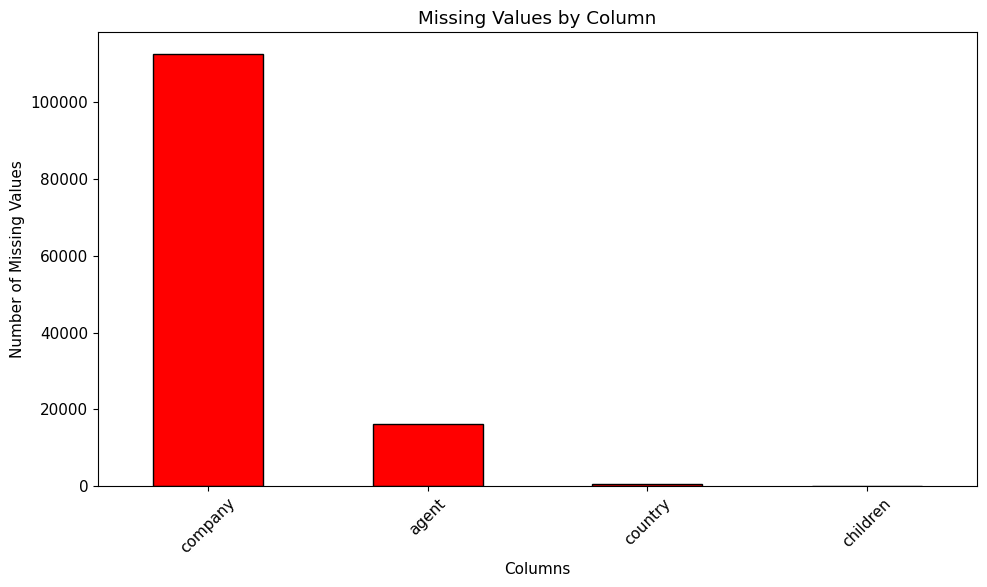

In [25]:


plt.figure(figsize=(10, 6))

missing_summary['Missing Values'].plot(
    kind='bar',
    color='red',
    edgecolor='black'
)

plt.title('Missing Values by Column')
plt.xlabel('Columns')
plt.ylabel('Number of Missing Values')

plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

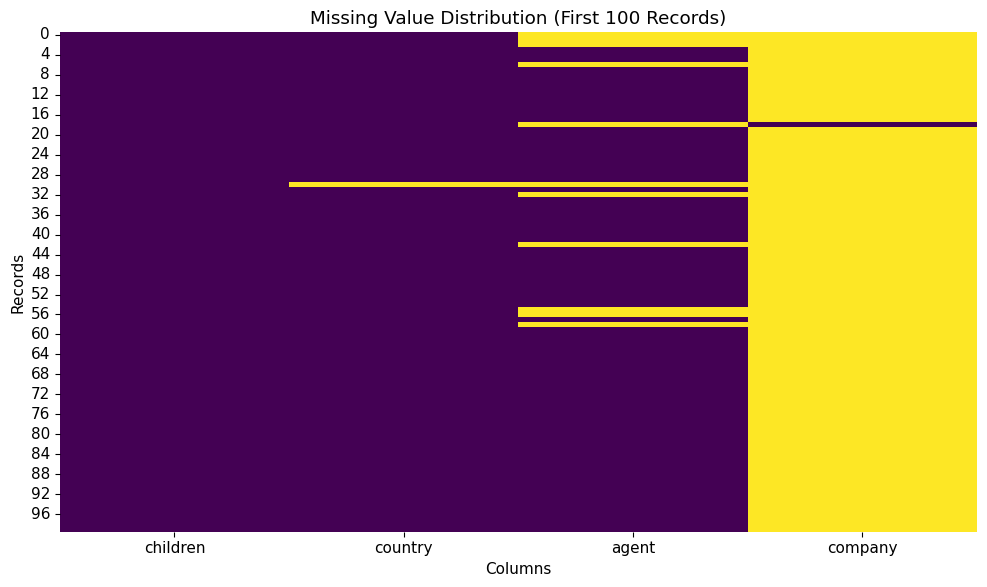

In [28]:
import seaborn as sns
missing_columns = df.columns[df.isnull().any()]
df.columns[df.isnull().any()]
plt.figure(figsize=(10, 6))
sns.heatmap(
    df[missing_columns].head(100).isnull(),
    cbar=False,
    cmap='viridis'
)
plt.title('Missing Value Distribution (First 100 Records)')
plt.xlabel('Columns')
plt.ylabel('Records')

plt.tight_layout()

### MISSING VALUES INTERPRETATION

The missing value analysis indicates that missing data is concentrated in a few columns(company , agent , country , children) rather than being uniformly distributed across the dataset. The company and agent columns require further investigation because they contain substantial missing information.We will not fill or delete missing values yet. First, we will investigate them and decide what to do based on the analysis objective.

DATA QUALITY ANALYSIS

In [29]:
# Count duplicate rows

duplicate_count = df.duplicated().sum()

print("Total duplicate records:", duplicate_count)

Total duplicate records: 31994


In [30]:
# Display duplicate records

duplicates = df[df.duplicated()]

print("Duplicate records:")
display(duplicates.head(10))

Duplicate records:


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
5,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.00,0,1,Check-Out,2015-07-03
22,Resort Hotel,0,72,2015,July,27,1,2,4,2,...,No Deposit,250.0,NaN,0,Transient,84.67,0,1,Check-Out,2015-07-07
43,Resort Hotel,0,70,2015,July,27,2,2,3,2,...,No Deposit,250.0,NaN,0,Transient,137.00,0,1,Check-Out,2015-07-07
138,Resort Hotel,1,5,2015,July,28,5,1,0,2,...,No Deposit,240.0,NaN,0,Transient,97.00,0,0,Canceled,2015-07-01
200,Resort Hotel,0,0,2015,July,28,7,0,1,1,...,No Deposit,240.0,NaN,0,Transient,109.80,0,3,Check-Out,2015-07-08
219,Resort Hotel,1,1,2015,July,28,8,0,1,2,...,No Deposit,NaN,110.0,0,Transient,104.72,0,1,Canceled,2015-07-08
256,Resort Hotel,0,91,2015,July,28,10,0,2,2,...,No Deposit,240.0,NaN,0,Transient,73.80,0,1,Check-Out,2015-07-12
261,Resort Hotel,0,30,2015,July,28,10,2,2,2,...,No Deposit,NaN,NaN,0,Transient-Party,197.00,0,1,Check-Out,2015-07-14
353,Resort Hotel,0,98,2015,July,29,13,1,1,2,...,No Deposit,240.0,NaN,0,Transient-Party,82.00,0,3,Check-Out,2015-07-15
372,Resort Hotel,0,40,2015,July,29,13,1,4,2,...,No Deposit,250.0,NaN,0,Transient,120.00,0,2,Check-Out,2015-07-18


In [31]:
#  duplicate percentage

duplicate_percentage = (duplicate_count / len(df)) * 100

print("Duplicate percentage:", round(duplicate_percentage, 2), "%")

Duplicate percentage: 26.8 %


In [32]:
#  data type summary

dtype_summary = pd.DataFrame({
    'Column': df.columns,
    'Data Type': df.dtypes.values
})

display(dtype_summary)

,Column,Data Type
0,hotel,object
1,is_canceled,int64
2,lead_time,int64
3,arrival_date_year,int64
4,arrival_date_month,object
5,arrival_date_week_number,int64
6,arrival_date_day_of_month,int64
7,stays_in_weekend_nights,int64
8,stays_in_week_nights,int64
9,adults,int64


In [33]:
 #unique values in each categorical column

for col in categorical_columns:
    print(f"\nColumn: {col}")
    print(df[col].unique()[:20])


Column: hotel
['Resort Hotel' 'City Hotel']

Column: arrival_date_month
['July' 'August' 'September' 'October' 'November' 'December' 'January'
 'February' 'March' 'April' 'May' 'June']

Column: meal
['BB' 'FB' 'HB' 'SC' 'Undefined']

Column: country
['PRT' 'GBR' 'USA' 'ESP' 'IRL' 'FRA' nan 'ROU' 'NOR' 'OMN' 'ARG' 'POL'
 'DEU' 'BEL' 'CHE' 'CN' 'GRC' 'ITA' 'NLD' 'DNK']

Column: market_segment
['Direct' 'Corporate' 'Online TA' 'Offline TA/TO' 'Complementary' 'Groups'
 'Undefined' 'Aviation']

Column: distribution_channel
['Direct' 'Corporate' 'TA/TO' 'Undefined' 'GDS']

Column: reserved_room_type
['C' 'A' 'D' 'E' 'G' 'F' 'H' 'L' 'P' 'B']

Column: assigned_room_type
['C' 'A' 'D' 'E' 'G' 'F' 'I' 'B' 'H' 'P' 'L' 'K']

Column: deposit_type
['No Deposit' 'Refundable' 'Non Refund']

Column: customer_type
['Transient' 'Contract' 'Transient-Party' 'Group']

Column: reservation_status
['Check-Out' 'Canceled' 'No-Show']

Column: reservation_status_date
['2015-07-01' '2015-07-02' '2015-07-03' '2015

In [34]:
# Numerical summary statistics

df.describe()

,is_canceled,lead_time,arrival_date_year,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,booking_changes,agent,company,days_in_waiting_list,adr,required_car_parking_spaces,total_of_special_requests
count,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119386.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,103050.000000,6797.000000,119390.000000,119390.000000,119390.000000,119390.000000
mean,0.370416,104.011416,2016.156554,27.165173,15.798241,0.927599,2.500302,1.856403,0.103890,0.007949,0.031912,0.087118,0.137097,0.221124,86.693382,189.266735,2.321149,101.831122,0.062518,0.571363
std,0.482918,106.863097,0.707476,13.605138,8.780829,0.998613,1.908286,0.579261,0.398561,0.097436,0.175767,0.844336,1.497437,0.652306,110.774548,131.655015,17.594721,50.535790,0.245291,0.792798
min,0.000000,0.000000,2015.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,6.000000,0.000000,-6.380000,0.000000,0.000000
25%,0.000000,18.000000,2016.000000,16.000000,8.000000,0.000000,1.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,9.000000,62.000000,0.000000,69.290000,0.000000,0.000000
50%,0.000000,69.000000,2016.000000,28.000000,16.000000,1.000000,2.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,14.000000,179.000000,0.000000,94.575000,0.000000,0.000000
75%,1.000000,160.000000,2017.000000,38.000000,23.000000,2.000000,3.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,229.000000,270.000000,0.000000,126.000000,0.000000,1.000000
max,1.000000,737.000000,2017.000000,53.000000,31.000000,19.000000,50.000000,55.000000,10.000000,10.000000,1.000000,26.000000,72.000000,21.000000,535.000000,543.000000,391.000000,5400.000000,8.000000,5.000000


In [35]:
# unusual values in booking variables

print("Negative lead time:",
      (df['lead_time'] < 0).sum())

print("Negative adults:",
      (df['adults'] < 0).sum())

print("Negative children:",
      (df['children'] < 0).sum())

print("Negative ADR:",
      (df['adr'] < 0).sum())
print("Bookings with zero adults:",
      (df['adults'] == 0).sum())

print("Bookings with zero ADR:",
      (df['adr'] == 0).sum())

Negative lead time: 0
Negative adults: 0
Negative children: 0
Negative ADR: 1
Bookings with zero adults: 403
Bookings with zero ADR: 1959


### VISUALIZATION 2 boxplot for lead time

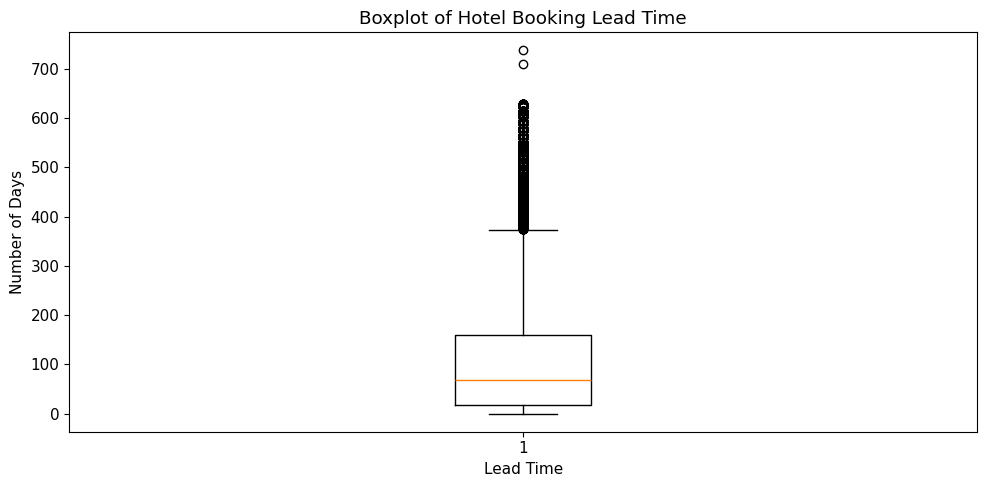

In [36]:
plt.figure(figsize=(10, 5))

plt.boxplot(df['lead_time'].dropna())

plt.title('Boxplot of Hotel Booking Lead Time')
plt.xlabel('Lead Time')
plt.ylabel('Number of Days')

plt.tight_layout()
plt.show()

### Interpretation: Visualization 2 (Boxplot of Lead Time)

This boxplot reveals that hotel booking lead times are heavily right-skewed. The median lead time is relatively low (69 days), but the distribution stretches far to the right, showing a long tail of guests booking up to 2 years (737 days) in advance. The IQR method flags 3,005 bookings as potential statistical outliers on the upper end (above 373 days).

DETECTING OUTLIERS USING IQR METHOD

In [37]:
Q1 = df['lead_time'].quantile(0.25)
Q3 = df['lead_time'].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)

print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)

# Identify outliers

outliers = df[
    (df['lead_time'] < lower_bound) |
    (df['lead_time'] > upper_bound)
]

print("Number of potential outliers:", len(outliers))

Q1: 18.0
Q3: 160.0
IQR: 142.0
Lower Bound: -195.0
Upper Bound: 373.0
Number of potential outliers: 3005


data quality summary

In [38]:
# Data quality summary

quality_summary = pd.DataFrame({
    'Metric': [
        'Total Rows',
        'Total Columns',
        'Duplicate Records',
        'Missing Cells',
        'Negative Lead Time',
        'Negative Adults',
        'Negative ADR',
        'Potential Lead Time Outliers'
    ],

    'Value': [
        df.shape[0],
        df.shape[1],
        df.duplicated().sum(),
        df.isnull().sum().sum(),
        (df['lead_time'] < 0).sum(),
        (df['adults'] < 0).sum(),
        (df['adr'] < 0).sum(),
        len(outliers)
    ]
})

display(quality_summary)

,Metric,Value
0,Total Rows,119390
1,Total Columns,32
2,Duplicate Records,31994
3,Missing Cells,129425
4,Negative Lead Time,0
5,Negative Adults,0
6,Negative ADR,1
7,Potential Lead Time Outliers,3005


### Data Quality Findings

. Duplicate Records:
   The dataset contains 31994 duplicate records.

. Missing Data:
   The columns with the highest missing values are 129425

. Data Types:
   The dataset contains numerical and categorical variables.
   



.Outliers:
   The IQR method identified 3005 potential outliers
   in the lead_time column.

### Conclusion

The dataset contains certain data-quality issues that
should be considered during further analysis. However,
potential outliers and unusual records should not be
automatically removed without understanding their context.

STATISTICAL ANALYSIS TO THE UNUSUAL VALUES





In [39]:
negative_adr = df[df['adr'] < 0]

print("Negative ADR records:", len(negative_adr))

display(negative_adr.head())

Negative ADR records: 1


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
14969,Resort Hotel,0,195,2017,March,10,5,4,6,2,...,No Deposit,273.0,NaN,0,Transient-Party,-6.38,0,0,Check-Out,2017-03-15


In [40]:
high_adr = df[df['adr'] > 1000]

print("ADR values above 1000:", len(high_adr))

display(high_adr[['hotel', 'adr', 'adults', 'children']].head(10))

ADR values above 1000: 1


,hotel,adr,adults,children
48515,City Hotel,5400.0,2,0.0


In [41]:
zero_adults = df[df['adults'] == 0]

print("Bookings with zero adults:", len(zero_adults))

display(zero_adults.head())

Bookings with zero adults: 403


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
2224,Resort Hotel,0,1,2015,October,41,6,0,3,0,...,No Deposit,NaN,174.0,0,Transient-Party,0.0,0,0,Check-Out,2015-10-06
2409,Resort Hotel,0,0,2015,October,42,12,0,0,0,...,No Deposit,NaN,174.0,0,Transient,0.0,0,0,Check-Out,2015-10-12
3181,Resort Hotel,0,36,2015,November,47,20,1,2,0,...,No Deposit,38.0,NaN,0,Transient-Party,0.0,0,0,Check-Out,2015-11-23
3684,Resort Hotel,0,165,2015,December,53,30,1,4,0,...,No Deposit,308.0,NaN,122,Transient-Party,0.0,0,0,Check-Out,2016-01-04
3708,Resort Hotel,0,165,2015,December,53,30,2,4,0,...,No Deposit,308.0,NaN,122,Transient-Party,0.0,0,0,Check-Out,2016-01-05


In [42]:
quality_summary = pd.DataFrame({
    'Issue': [
        'Negative ADR',
        'ADR above 1000',
        'Zero adults'
    ],
    'Count': [
        (df['adr'] < 0).sum(),
        (df['adr'] > 1000).sum(),
        (df['adults'] == 0).sum()
    ]
})

quality_summary['Percentage'] = (
    quality_summary['Count'] / len(df) * 100
)

display(quality_summary)

,Issue,Count,Percentage
0,Negative ADR,1,0.000838
1,ADR above 1000,1,0.000838
2,Zero adults,403,0.337549


### Initial Statistical Observations

1. **Booking Cancellation:** The average of the `is_canceled` variable is approximately 0.3704, indicating that around 37.04% of bookings were canceled.

2. **Booking Lead Time:** The mean lead time is approximately 104 days, whereas the median is 69 days. This difference suggests a right-skewed distribution.

3. **Customer Composition:** The median number of adults is 2, while the third quartile of children is 0, indicating that most bookings do not include children.

4. **ADR Anomalies:** The ADR variable contains negative values and an unusually high maximum of 5400, which require further investigation.

5. **Missing Observations:** The company and agent columns have substantial missing observations, which should be considered when performing subsequent analysis.

**Conclusion:** The descriptive statistics reveal useful patterns in customer booking behaviour and identify potential data-quality issues that need further investigation before drawing final conclusions.

In [43]:
# Select important numerical columns

selected_columns = [
    'lead_time',
    'adr',
    'adults',
    'children',
    'stays_in_week_nights'
]

# Calculate statistical measures

statistics_summary = pd.DataFrame({
    'Mean': df[selected_columns].mean(),
    'Median': df[selected_columns].median(),
    'Mode': df[selected_columns].mode().iloc[0],
    'Standard Deviation': df[selected_columns].std(),
    'Variance': df[selected_columns].var()
})

display(statistics_summary.round(2))

,Mean,Median,Mode,Standard Deviation,Variance
lead_time,104.01,69.00,0.0,106.86,11419.72
adr,101.83,94.58,62.0,50.54,2553.87
adults,1.86,2.00,2.0,0.58,0.34
children,0.10,0.00,0.0,0.40,0.16
stays_in_week_nights,2.50,2.00,2.0,1.91,3.64


EDA VISUALIZATIONS

### Visualization 3: Distribution of Booking Lead Time

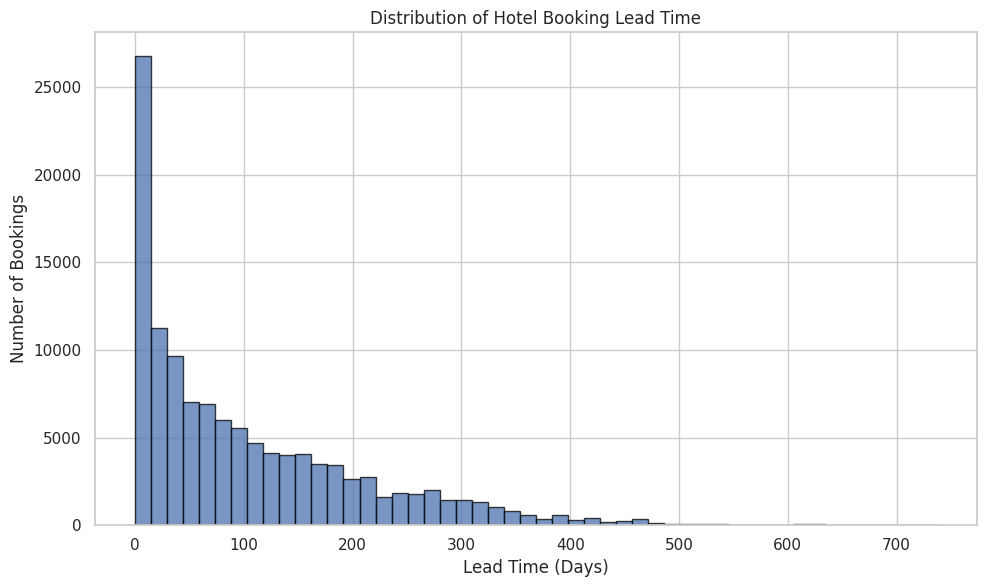

In [47]:
plt.figure(figsize=(10, 6))

plt.hist(
    df['lead_time'],
    bins=50,
    edgecolor='black',
    alpha=0.75
)

plt.title('Distribution of Hotel Booking Lead Time')
plt.xlabel('Lead Time (Days)')
plt.ylabel('Number of Bookings')

plt.tight_layout()
plt.show()

### Interpretation: Visualization 3 (Distribution of Booking Lead Time)

The histogram highlights that hotel bookings are highly concentrated around a lead time of 0 to 50 days. This indicates that a vast proportion of customers book their stay spontaneously or very close to their arrival date. As lead time increases, the volume of bookings decays significantly, illustrating a strongly right-skewed, exponential-like decay distribution.

Visualization 4: Booking Cancellation Distribution

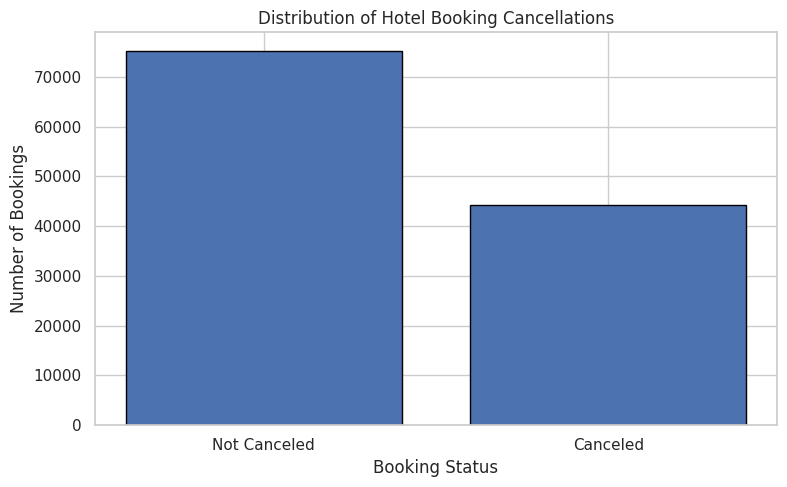

In [48]:


cancellation_counts = df['is_canceled'].value_counts().sort_index()

plt.figure(figsize=(8, 5))

plt.bar(
    ['Not Canceled', 'Canceled'],
    cancellation_counts.values,
    edgecolor='black'
)

plt.title('Distribution of Hotel Booking Cancellations')
plt.xlabel('Booking Status')
plt.ylabel('Number of Bookings')

plt.tight_layout()
plt.show()

### Interpretation: Visualization 4 (Booking Cancellation Distribution)

This visualization highlights a major operational challenge for the hospitality management: approximately 37% of all bookings in this dataset were canceled (`is_canceled = 1`). Such a high volume of cancellations represents a significant risk for room inventory management, forecasting, and overall revenue stability.

Visualization 5: Monthly Booking Trends

arrival_date_month
January       5929
February      8068
March         9794
April        11089
May          11791
June         10939
July         12661
August       13877
September    10508
October      11160
November      6794
December      6780
Name: count, dtype: int64


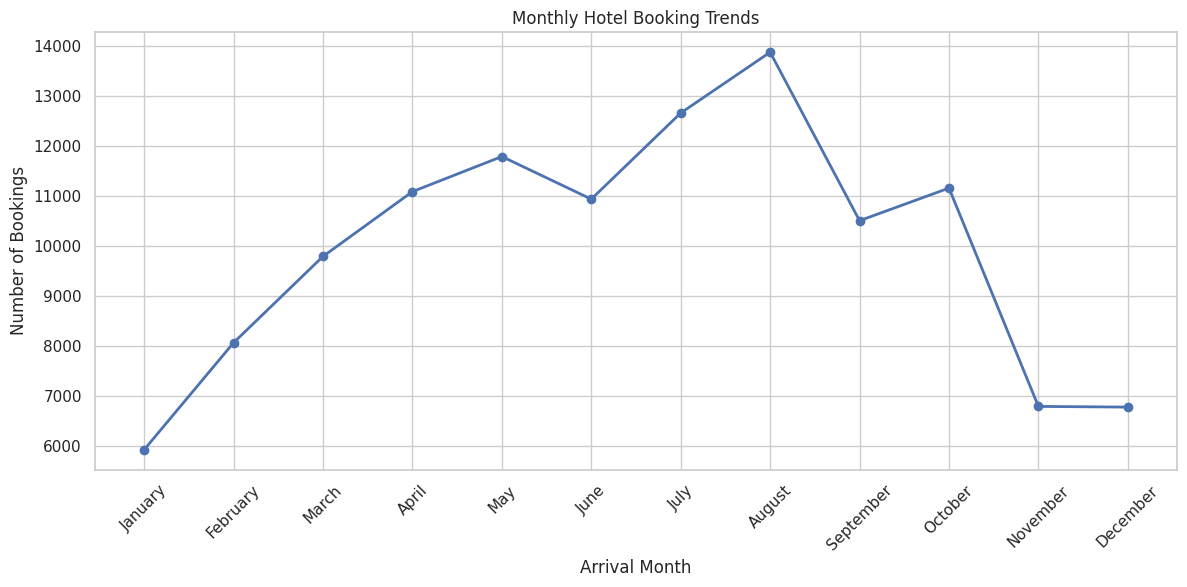

In [50]:
# Define calendar month order

month_order = [
    'January', 'February', 'March',
    'April', 'May', 'June',
    'July', 'August', 'September',
    'October', 'November', 'December'
]



monthly_bookings = (
    df['arrival_date_month']
    .value_counts()
    .reindex(month_order)
)

print(monthly_bookings)

plt.figure(figsize=(12, 6))

plt.plot(
    monthly_bookings.index,
    monthly_bookings.values,
    marker='o',
    linewidth=2
)

plt.title('Monthly Hotel Booking Trends')
plt.xlabel('Arrival Month')
plt.ylabel('Number of Bookings')

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

### Interpretation: Visualization 5 (Monthly Booking Trends)

This line plot shows clear seasonal demand for hotel bookings. Guest arrivals peak during the summer months, specifically July (12,661) and August (13,877). Conversely, bookings decline significantly during winter, reaching their lowest points in November (6,794), December (6,780), and January (5,929), which suggests a strong holiday-driven and weather-dependent booking cycle.

Visualization 6: Market Segment Analysis

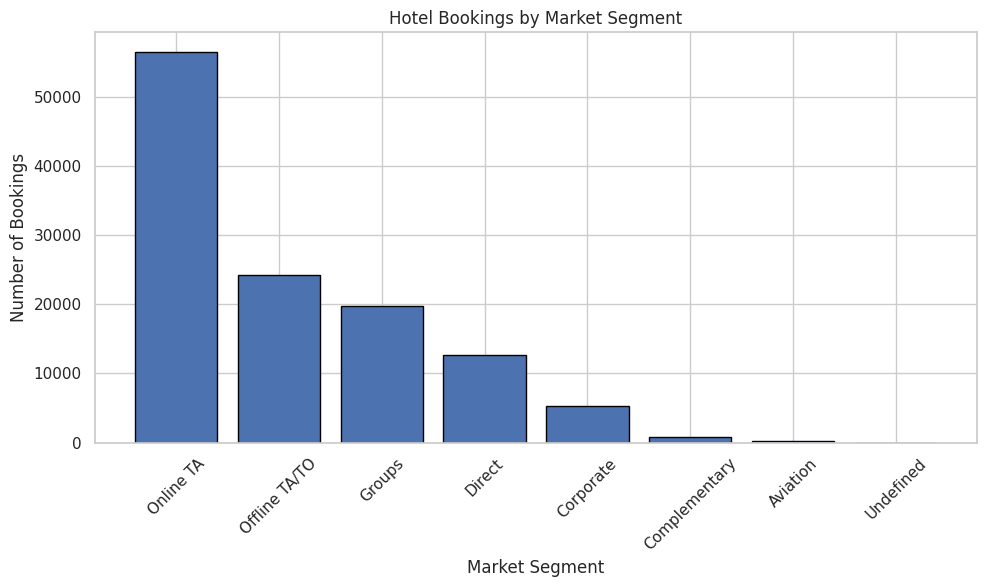

In [51]:
market_counts = df['market_segment'].value_counts()

plt.figure(figsize=(10, 6))

plt.bar(
    market_counts.index,
    market_counts.values,
    edgecolor='black'
)

plt.title('Hotel Bookings by Market Segment')
plt.xlabel('Market Segment')
plt.ylabel('Number of Bookings')

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

### Interpretation: Visualization 6 (Market Segment Analysis)

This bar chart clearly demonstrates that Online Travel Agents (Online TA) represent the overwhelming majority of bookings, with over 56,000 entries. Combined with Offline TA/TO and Direct bookings, intermediaries and direct digital customer acquisitions dominate the distribution channels. Traditional corporate and aviation segments, by comparison, contribute minimally to the total volume.

Visualization 7: ADR Distribution by Hotel Type

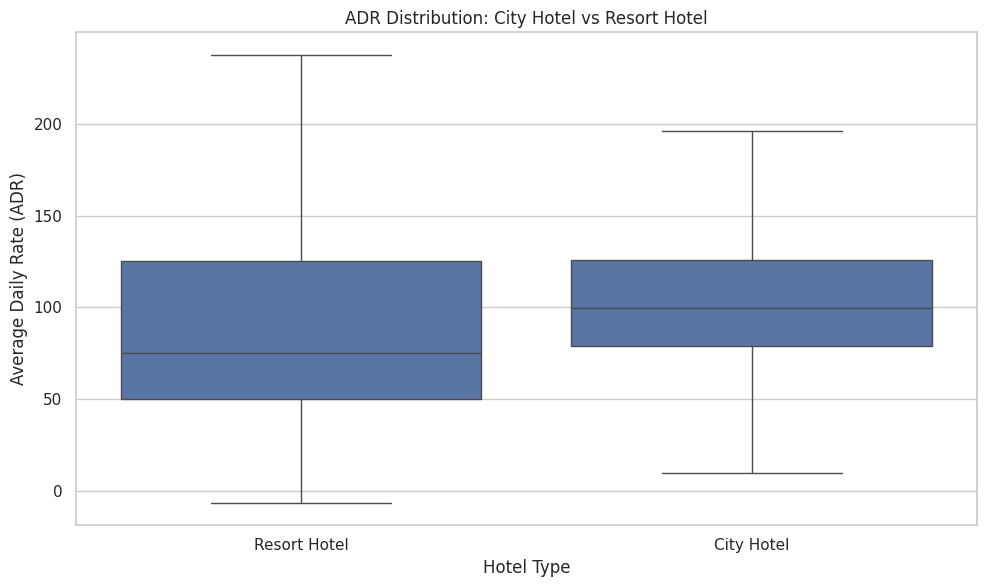

In [52]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x='hotel',
    y='adr',
    showfliers=False
)

plt.title('ADR Distribution: City Hotel vs Resort Hotel')
plt.xlabel('Hotel Type')
plt.ylabel('Average Daily Rate (ADR)')

plt.tight_layout()
plt.show()

### Interpretation: Visualization 7 (ADR Distribution by Hotel Type)

This side-by-side boxplot compares the Average Daily Rate (ADR) distribution for City Hotels versus Resort Hotels (excluding extreme outliers). City Hotels tend to have a slightly higher median ADR (~$100) and a more concentrated distribution. On the other hand, Resort Hotels show a lower median rate (~$75) but exhibit greater price variability, likely due to seasonal vacation pricing fluctuations.

Visualization 8: Hotel Type vs Cancellation Rate

hotel
City Hotel      41.73
Resort Hotel    27.76
Name: is_canceled, dtype: float64


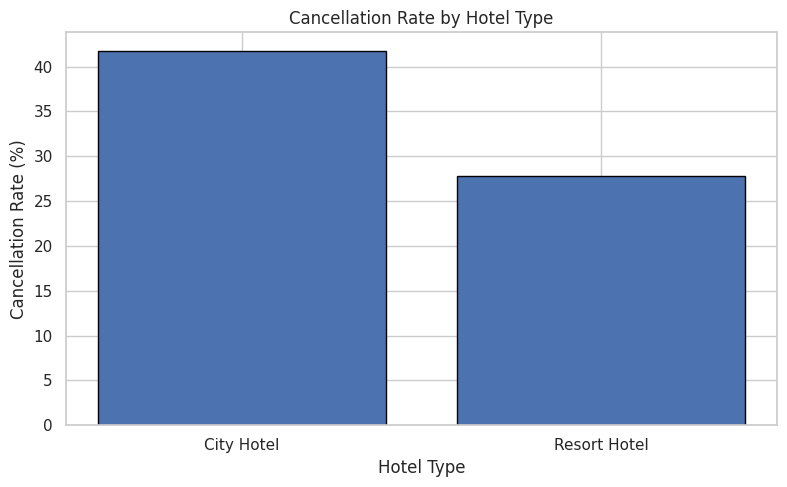

In [54]:
cancellation_rates = (
    df.groupby('hotel')['is_canceled'].mean() * 100
)

print(cancellation_rates.round(2))

plt.figure(figsize=(8, 5))

plt.bar(
    cancellation_rates.index,
    cancellation_rates.values,
    edgecolor='black'
)

plt.title('Cancellation Rate by Hotel Type')
plt.xlabel('Hotel Type')
plt.ylabel('Cancellation Rate (%)')

plt.tight_layout()
plt.show()

### Interpretation: Visualization 8 (Hotel Type vs Cancellation Rate)

This comparison reveals a stark difference in cancellation behavior between the two hotel types. **City Hotels** experience a much higher cancellation rate of **41.73%**, whereas **Resort Hotels** have a significantly lower cancellation rate of **27.76%**. This suggests that urban bookings may be more prone to plans changing, business trip adjustments, or short-notice changes, while resort trips—often representing pre-planned vacations—exhibit higher commitment from guests.

Visualization 9: Correlation Heatmap

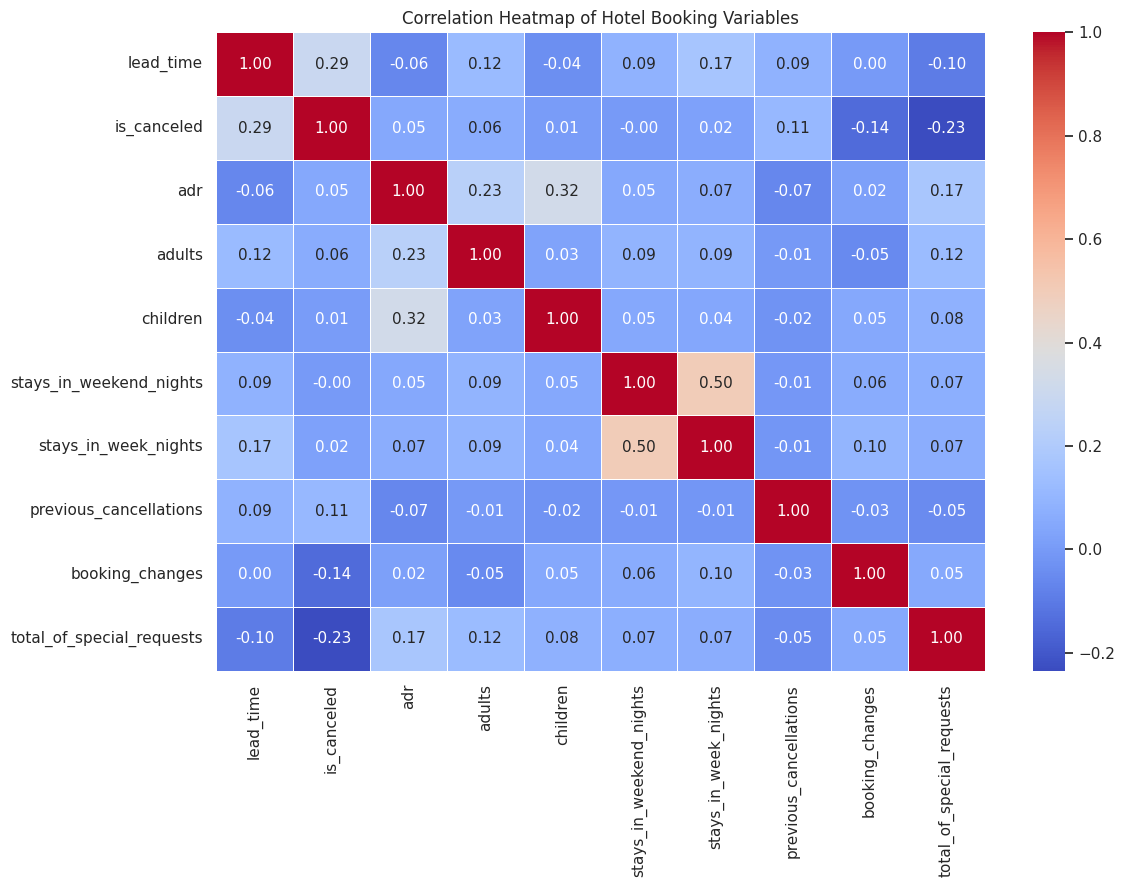

In [55]:


correlation_columns = [
    'lead_time',
    'is_canceled',
    'adr',
    'adults',
    'children',
    'stays_in_weekend_nights',
    'stays_in_week_nights',
    'previous_cancellations',
    'booking_changes',
    'total_of_special_requests'
]

# Calculate correlation

correlation_matrix = df[correlation_columns].corr()



plt.figure(figsize=(12, 9))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Correlation Heatmap of Hotel Booking Variables')

plt.tight_layout()
plt.show()

### Interpretation: Visualization 9 (Correlation Heatmap)

The correlation heatmap highlights several interesting patterns among the booking variables:

* **Weak Correlations Overall:** Most variables show very weak linear relationships, indicating that booking behavior is influenced by complex, multi-dimensional factors rather than single direct drivers.
* **Lead Time & Cancellations:** There is a weak positive correlation (**0.29**) between `lead_time` and `is_canceled`, suggesting that bookings made far in advance are slightly more likely to be canceled.
* **ADR & Guests:** A moderate positive correlation (**0.23**) exists between `adr` (Average Daily Rate) and `adults`, which is intuitive since pricing typically scales with the number of guests in a room.
* **Stays & Weekends/Weekdays:** There is a moderate positive correlation (**0.49**) between weekend stays and weekday stays, showing that guests who book longer trips generally extend their stay across both weekdays and weekends.

Visualization 10: Top 10 Customer Countries

country
PRT    48590
GBR    12129
FRA    10415
ESP     8568
DEU     7287
ITA     3766
IRL     3375
BEL     2342
BRA     2224
NLD     2104
Name: count, dtype: int64


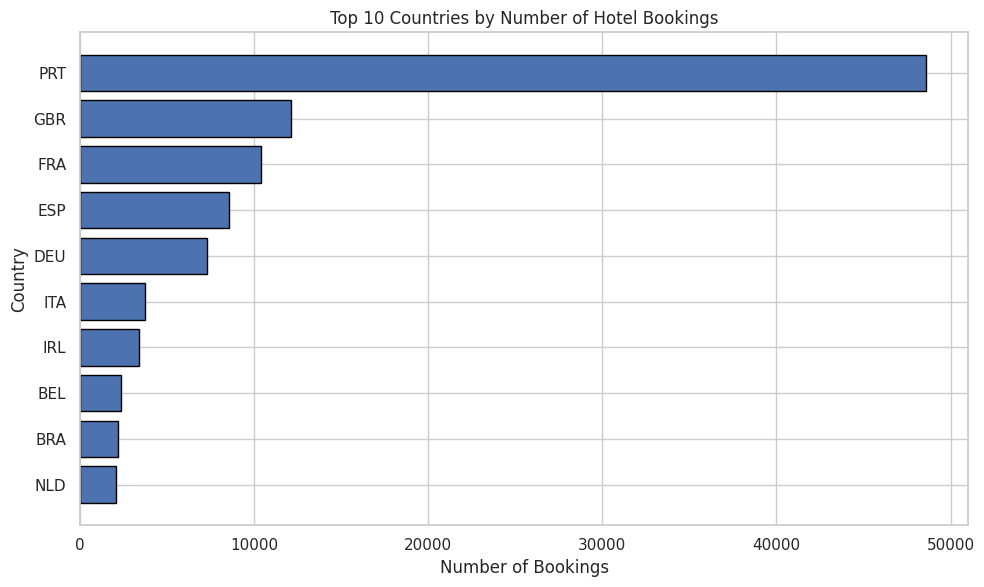

In [57]:
# Count bookings by country

country_counts = (
    df['country']
    .value_counts()
    .head(10)
)

print(country_counts)
plt.figure(figsize=(10, 6))

plt.barh(
    country_counts.index[::-1],
    country_counts.values[::-1],
    edgecolor='black'
)

plt.title('Top 10 Countries by Number of Hotel Bookings')
plt.xlabel('Number of Bookings')
plt.ylabel('Country')

plt.tight_layout()
plt.show()

### Interpretation: Visualization 10 (Top 10 Countries by Number of Hotel Bookings)

This horizontal bar chart highlights the geographical origins of the hotel guests:

* **Dominance of Portugal (PRT):** Portugal is by far the single largest source market with **48,590** bookings. This is expected given that the dataset originates from hotels in Portugal.
* **Strong European Market:** The remaining top source countries are predominantly European, led by the United Kingdom (GBR, ~12K), France (FRA, ~10K), Spain (ESP, ~8.5K), and Germany (DEU, ~7.2K).
* **Intercontinental Representation:** Brazil (BRA) is the only non-European country to appear in the top 10 list, highlighting a notable intercontinental tourism link, likely influenced by shared language and cultural ties.

# Executive Summary of EDA Findings

Having explored and visualized the hotel booking data, here are the **5 most critical insights and takeaways** from this dataset:

### 1. High Cancellation Risk (Operational Pain Point)
With a baseline cancellation rate of **~37%**, cancellations represent a massive operational challenge. Interestingly, **City Hotels** experience a vastly higher cancellation rate (**41.73%**) compared to **Resort Hotels** (**27.76%**). This suggests hotel managers in city centers should consider tighter reservation structures, non-refundable deposit strategies, or active overbooking algorithms.

### 2. Spontaneous Booking Cycles (Right-Skewed Lead Time)
Although some guests plan their trips up to two years in advance, the vast majority of hotel bookings are highly spontaneous. The **median lead time is just 69 days**, with a massive concentration of bookings occurring within 0 to 50 days of arrival. This emphasizes the importance of real-time dynamic pricing and last-minute marketing campaigns.

### 3. Clear Seasonal Peaks (Weather-Dependent Booking)
Hotel demand is heavily holiday- and weather-driven, exhibiting a classic seasonal curve. Peak demand occurs in the summer—specifically **August (13,877 bookings)** and **July (12,661 bookings)**. Conversely, bookings plummet to their lowest levels during winter (averaging only ~6,000 bookings in November, December, and January).

### 4. Overwhelming OTA Dominance (Distribution Power)
Over **56,000 bookings** come through **Online Travel Agencies (Online TA)**, dwarfing direct bookings, corporate agreements, group packages, and traditional offline tour operators. While OTAs bring high volume, they also demand commissions, meaning hotels can increase profitability by investing in loyalty programs or direct-booking incentives.

### 5. Strong Domestic and Regional Footprint
**Portugal (PRT)** is by far the single largest source market with **48,590 bookings**, indicating strong domestic support. The remainder of the top 10 customer list is dominated by Western European nations (UK, France, Spain, and Germany). Brazil is the lone non-European country in the top list, showcasing a specific transatlantic market corridor.